# S09 · 边缘分布与随机化 PIT

> **Day 9 / 14** ｜ 对应论文章节 **3.7.2（Marginal models）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 说清楚为什么不能一直用经验分布，必须给边缘一个**参数形式**
- 识别并正确处理**截断**（duration 被 `min_len` 截到 ≥ 3）
- 用 AIC 在候选边缘之间选择，同时知道 AIC 什么时候不可比
- 实现**随机化 PIT**，把离散变量的平局修平
- 用 PIT 均匀性做边缘拟合优度检验

---

## 1. 为什么必须参数化边缘

S08 用 `rank/(n+1)` 得到伪观测，已经足够看清依赖结构。但正式建模必须参数化，原因有三：

| 理由 | 说明 |
|---|---|
| **外推** | 经验分布的上限是 `1 − 1/(n+1) ≈ 0.989`，对应重现期上限约 90 年。要问「50 年一遇」，经验分布**根本没有定义** |
| **平滑** | n = 90 时经验 CDF 是阶梯函数，每一步都是噪声。参数模型借用形状信息 |
| **可复现** | 报告 `Gamma(k=5.63, θ=0.62)` 比报告一张 ECDF 图更可检验 |

> 📌 论文里要写明这是 **IFM（Inference Functions for Margins）** 两步法：
> 先分别拟合两个边缘，再对 PIT 后的伪观测拟合 copula。**不是**联合最大似然。

---

## 2. 加载数据

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
ev <- load_catalogue()
STATION <- "Kuantan"
DEFN    <- "Tmax"

evx <- ev[ev$station == STATION & ev$defn == DEFN, ]
dur <- evx$duration
int <- evx$intensity

cat("n =", length(dur), "\n")
cat("duration 范围:", range(dur), " (最小值为", CFG$min_len, "，是被截断的)\n")
cat("intensity 范围:", round(range(int), 2), "\n")

n = 90 


duration 范围: 3 13  (最小值为 3 ，是被截断的)


intensity 范围: 0.5 3.6 


---

## 3. duration 是**截断**的，不是普通的离散分布

这一点极易被忽略，但会直接让边缘拟合出错。

事件定义里 `min_len = 3`，意味着**长度 1 天和 2 天的热浪根本没有进入样本**。
我们观测到的 `duration` 服从的是**条件分布**：

$$P(D = d \mid D \ge 3) = \frac{p(d)}{1 - F(2)}, \quad d = 3,4,5,\dots$$

如果按普通几何分布去拟合，模型会认为「有大量 1–2 天的事件」，从而把整体尺度压小 —— 参数偏差。

In [3]:
# 截断负二项 vs 截断几何（两者都定义在 d >= 3 上，AIC 可直接比较）
fit_nb_trunc <- function(x, L) {
  nll <- function(par) {
    size <- exp(par[1]); mu <- exp(par[2])
    den  <- pnbinom(L - 1, size = size, mu = mu, lower.tail = FALSE)
    -sum(log(dnbinom(x, size = size, mu = mu) / den))
  }
  optim(c(log(2), log(mean(x))), nll, method = "BFGS")
}

fit_geo_trunc <- function(x, L) {
  nll <- function(par) {
    p   <- plogis(par)
    den <- pgeom(L - 1, prob = p, lower.tail = FALSE)
    -sum(log(dgeom(x, prob = p) / den))
  }
  optim(log(0.3), nll, method = "BFGS")
}

L  <- CFG$min_len
nb <- fit_nb_trunc(dur, L)
ge <- fit_geo_trunc(dur, L)

aic <- data.frame(
  model   = c("NB (truncated)", "Geometric (truncated)"),
  k       = c(2, 1),
  logLik  = c(-nb$value, -ge$value),
  AIC     = c(2 * 2 + 2 * nb$value, 2 * 1 + 2 * ge$value)
)
aic$dAIC <- round(aic$AIC - min(aic$AIC), 2)
print(aic, row.names = FALSE)

                 model k    logLik      AIC dAIC
        NB (truncated) 2 -149.3520 302.7041 1.98
 Geometric (truncated) 1 -149.3602 300.7205 0.00


In [4]:
# 忽略截断会怎样？
raw_nb <- MASS::fitdistr(dur, "negative binomial")
cat("忽略截断的 NB 参数: size =", round(raw_nb$estimate["size"], 2),
    ", mu =", round(raw_nb$estimate["mu"], 2), "\n")
cat("考虑截断的 NB 参数: size =", round(exp(nb$par[1]), 2),
    ", mu =", round(exp(nb$par[2]), 2), "\n")

忽略截断的 NB 参数: size = 282.82 , mu = 4.46 


考虑截断的 NB 参数: size = 0.85 , mu = 1.31 


> 🔍 **两个 `mu` 差了好几倍。** 忽略截断的那次拟合认为「潜在的事件长度均值只有 4.5」，
> 但它同时预测了约 30% 的 1–2 天事件 —— 而我们的样本里这些事件被定义排除了。
> 这个模型**不能**用来对 `duration` 求分位数。
>
> ⚠️ 注意：截断模型与不截断模型的 AIC **不可直接比较**（似然定义在不同样本空间上）。
> AIC 只能在「同为截断」的 NB 与几何之间比较 —— 这才是上面那张表的意义。

> 📌 **AIC 结果告诉我们什么**：如果几何分布只差 1–2 个 AIC 点，说明 NB 的额外参数（size）不划算。
> **用更简单的模型**。奥卡姆剃刀在这里不是美学偏好，而是防止过拟合 90 个样本。

---

## 4. intensity：连续边缘的三选一

`intensity` 没有截断问题（事件一旦成立，超出量就可以是任意小的正数），但它是强右偏的。

In [5]:
cand <- c("gamma", "weibull", "lognormal")

fit_int <- lapply(cand, function(f) {
  suppressWarnings(MASS::fitdistr(int, f))
})
names(fit_int) <- cand

int_tab <- data.frame(
  model  = cand,
  k      = sapply(fit_int, function(f) length(f$estimate)),
  AIC    = sapply(fit_int, AIC)
)
int_tab$dAIC <- round(int_tab$AIC - min(int_tab$AIC), 2)
print(int_tab, row.names = FALSE)

     model k      AIC dAIC
     gamma 2 179.9401 0.00
   weibull 2 183.7498 3.81
 lognormal 2 182.2029 2.26


In [6]:
for (f in cand) {
  cat(sprintf("%-10s %s\n", f,
              paste(round(fit_int[[f]]$estimate, 3), collapse = ", ")))
}

gamma      5.631, 3.469
weibull    2.549, 1.832
lognormal  0.393, 0.44


> 📌 **AIC 差小于 2 时不要过度解读。** 三个候选的 AIC 差通常只有几个单位 ——
> 这说明数据无法区分它们。此时选择依据应该是**尾部行为**：
> - Gamma：轻尾（指数衰减）
> - Weibull：形状参数 > 1 时轻尾，< 1 时重尾
> - Lognormal：重尾
>
> **极端事件研究要关心尾部，所以不能只凭 AIC。** S14 会做边缘选择的敏感性分析。

---

## 5. 拟合优度：PIT 必须均匀

边缘拟合得好不好，有一个不依赖视觉的检验：**PIT 后的值应服从 U(0,1)**。

In [7]:
# 连续变量：直接代入 CDF
u_int <- pgamma(int,
                shape = fit_int$gamma$estimate["shape"],
                rate  = fit_int$gamma$estimate["rate"])

cat("intensity PIT: KS p =",
    round(suppressWarnings(ks.test(u_int, "punif"))$p.value, 4), "\n")

intensity PIT: KS p = 0.9267 


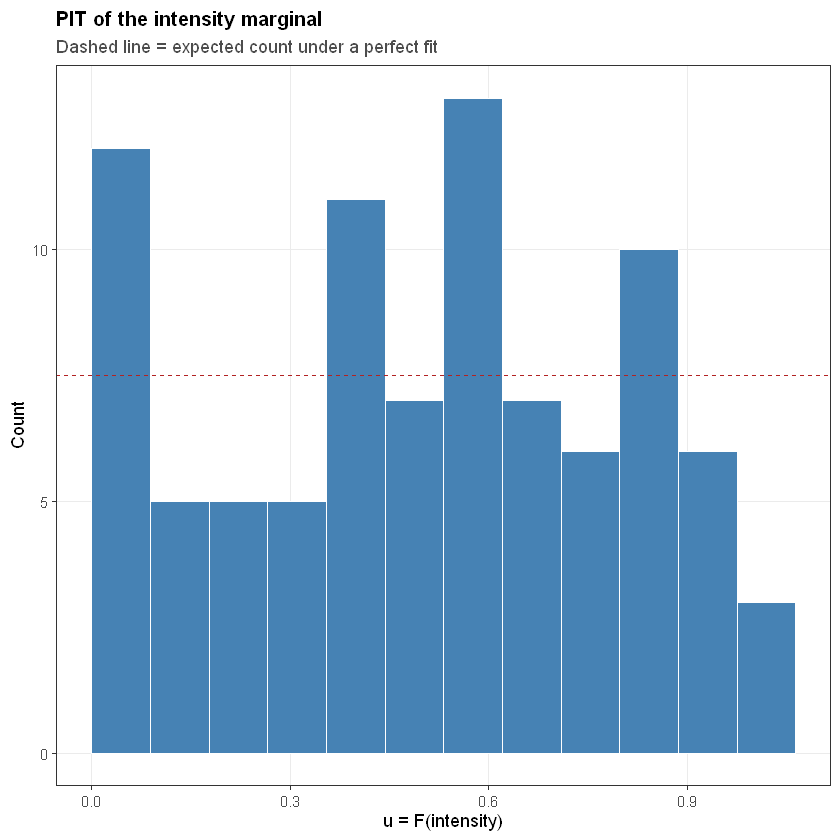

In [8]:
p_int_pit <- ggplot(data.frame(u = u_int), aes(u)) +
  geom_histogram(bins = 12, boundary = 0, fill = "steelblue", colour = "white") +
  geom_hline(yintercept = length(u_int) / 12, linetype = "dashed",
             colour = "firebrick") +
  labs(x = "u = F(intensity)", y = "Count",
       title = "PIT of the intensity marginal",
       subtitle = "Dashed line = expected count under a perfect fit") +
  theme_paper()

save_fig(p_int_pit, "S09_pit_intensity", 5.6, 3.8)
p_int_pit

> 🔍 直方图应当大致平坦。若呈 U 形 → 模型尾部太薄；若呈驼峰 → 太厚。
> 这是**比 KS 的 p 值更有信息量**的诊断，因为它告诉你是哪种错。

---

## 6. 随机化 PIT：离散变量的必修课

`duration` 是离散的。即使边缘拟合正确，同一天数的事件也会得到**完全相同**的 `u`，
在 copula 尺度上形成竖条 —— 这会人为制造「依赖」。

**随机化 PIT** 的做法：把同一个 `d` 对应的概率区间**均匀随机地分配**给这些事件。

$$u_i = F(d_i - 1 \mid D \ge 3) + W_i \cdot \big[F(d_i \mid D \ge 3) - F(d_i - 1 \mid D \ge 3)\big], \quad W_i \sim U(0,1)$$

In [9]:
set.seed(CFG$seed)

p_geom     <- plogis(ge$par)
pL         <- pgeom(L - 1, prob = p_geom)          # P(D <= 2)
F_trunc    <- function(q) (pgeom(q, prob = p_geom) - pL) / (1 - pL)

lo <- pmax(0, F_trunc(dur - 1))
hi <- F_trunc(dur)
u_dur_rand <- lo + runif(length(dur)) * (hi - lo)

# 对照：朴素的平均秩 PIT（有平局）
u_dur_rank <- rank(dur, ties.method = "average") / (length(dur) + 1)

cat("随机化 PIT 范围:", round(range(u_dur_rand), 3), "\n")
cat("KS p（随机化）:", round(suppressWarnings(ks.test(u_dur_rand, "punif"))$p.value, 4), "\n")

随机化 PIT 范围: 0.013 0.997 


KS p（随机化）: 0.9284 


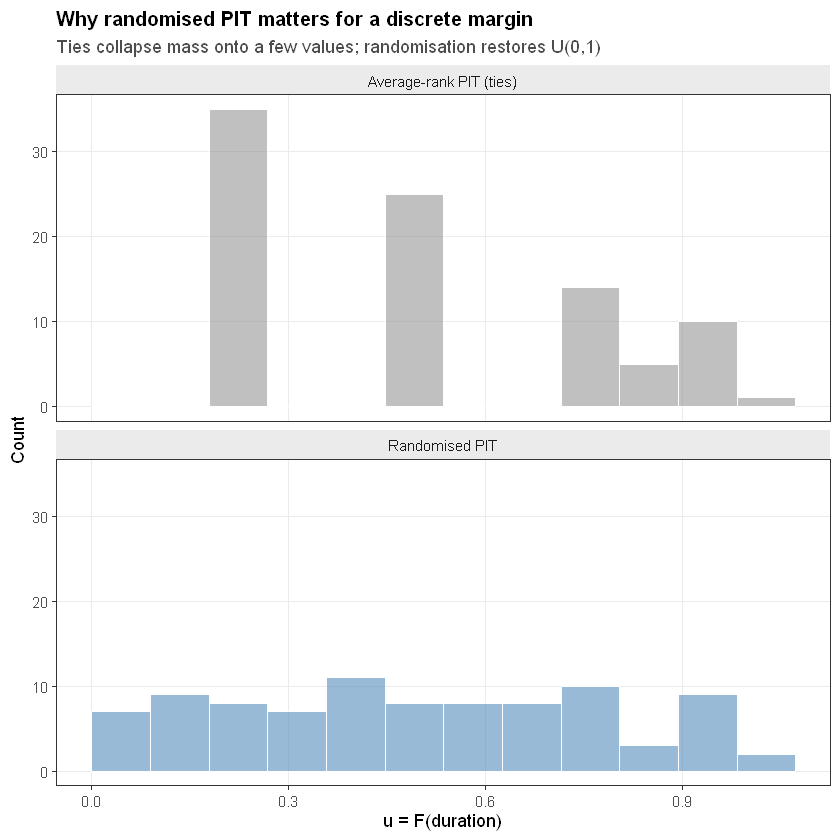

In [10]:
pit_df <- rbind(
  data.frame(u = u_dur_rank, method = "Average-rank PIT (ties)"),
  data.frame(u = u_dur_rand, method = "Randomised PIT")
)

p_pit <- ggplot(pit_df, aes(u, fill = method)) +
  geom_histogram(bins = 12, boundary = 0, position = "identity",
                 alpha = 0.55, colour = "white") +
  facet_wrap(~method, ncol = 1) +
  scale_fill_manual(values = c("Average-rank PIT (ties)" = "grey55",
                               "Randomised PIT" = "steelblue")) +
  labs(x = "u = F(duration)", y = "Count",
       title = "Why randomised PIT matters for a discrete margin",
       subtitle = "Ties collapse mass onto a few values; randomisation restores U(0,1)") +
  theme_paper() + theme(legend.position = "none")

save_fig(p_pit, "S09_pit_duration", 6.2, 5)
p_pit

> 🔍 **上图是本节的核心证据**：同一批事件，同一个边缘模型，
> 只因为处理平局的方式不同，一个在 copula 尺度上呈现尖峰，另一个是均匀的。
>
> ⚠️ **但随机化有代价，下一节必须算清楚。**

---

## 7. 随机化的代价：它会把 τ 稀释掉

这是整本手册里最容易被忽略、也最容易被审稿人抓住的一处。先看数字。

In [11]:
u_dur_mid <- (lo + hi) / 2      # 区间中点：同一 d 的所有事件取同一个值

tau_of <- function(a, b) round(cor(a, b, method = "kendall"), 4)
ks_of  <- function(a) round(suppressWarnings(ks.test(a, "punif"))$p.value, 4)

pit_cmp <- data.frame(
  version  = c("Raw values", "Average-rank PIT", "Mid-interval PIT", "Randomised PIT (1 draw)"),
  tau      = c(tau_of(dur, int), tau_of(u_dur_rank, u_int),
               tau_of(u_dur_mid, u_int), tau_of(u_dur_rand, u_int)),
  ks_p     = c(NA, ks_of(u_dur_rank), ks_of(u_dur_mid), ks_of(u_dur_rand))
)
print(pit_cmp, row.names = FALSE)

                 version    tau   ks_p
              Raw values 0.2951     NA
        Average-rank PIT 0.2951 0.0017
        Mid-interval PIT 0.2951 0.0011
 Randomised PIT (1 draw) 0.2316 0.9284


In [12]:
# 单次随机化不稳定：跑 50 次看它抖多少
set.seed(CFG$seed)
R <- 50
tau_rep <- replicate(R, {
  u <- lo + runif(length(dur)) * (hi - lo)
  cor(u, u_int, method = "kendall")
})

cat(sprintf("随机化 PIT 的 tau：均值 %.3f，标准差 %.3f，范围 %.3f - %.3f\n",
            mean(tau_rep), sd(tau_rep), min(tau_rep), max(tau_rep)))
cat(sprintf("原始 tau          ：%.3f\n", cor(dur, int, method = "kendall")))
cat(sprintf("稀释幅度          ：%.3f\n",
            cor(dur, int, method = "kendall") - mean(tau_rep)))

随机化 PIT 的 tau：均值 0.255，标准差 0.018，范围 0.221 - 0.297


原始 tau          ：0.295


稀释幅度          ：0.040


> 🔍 **为什么中点 PIT 的 τ 一点不变，随机化的 τ 却掉了一截？**
>
> 因为 τ 的不变性要求变换是**单调不减**的。中点 PIT 对 `duration` 是单调不减的
> （天数相同 → `u` 相同；天数更大 → `u` 更大），所以排序信息完全保留，τ 精确不变。
>
> 随机化 PIT 给同一 `d` 的事件**随机的顺序**。本例 `duration` 的平局极重
> （90 个事件里有 35 个都是 3 天），这些事件两两之间的先后关系被扔硬币决定，
> 一致性信息被稀释 —— **τ 系统性下降，而且每次运行还会抖动。**
>
> **这不是 bug，是随机化的固有性质。**

> 📌 **所以本手册的处理规则（可以直接写进方法章）：**
>
> | 用途 | 用哪个 PIT | 理由 |
> |---|---|---|
> | **Copula 参数拟合**（S10–S11） | **中点 PIT** | τ 精确保留，参数估计无偏 |
> | **边缘拟合优度检验** | 随机化 PIT | 只有它给出真正均匀的边际 |
> | **模拟 / 重现期外推**（S12） | 随机化 PIT | 需要连续取值才能求逆 |
>
> **论文里必须同时报告两件事**：原始数据的 τ（本例 0.30）和所用 PIT 版本。
> 如果只报随机化后的 τ 而不说明，读者会以为依赖比真实情况弱。

---

## 8. 产出：交给 S10 的 u 和 v

In [13]:
uv <- data.frame(u = u_dur_mid, v = u_int, u_rand = u_dur_rand,
                 duration = dur, intensity = int)

cat("用于拟合的 Kendall tau:", tau_of(uv$u, uv$v), "\n")
cat("原始数据的 Kendall tau:", tau_of(dur, int), "\n")
cat("随机化版本的 Kendall tau:", tau_of(uv$u_rand, uv$v), "\n")

saveRDS(uv, file.path(PATHS$mres, "S09_pit_pairs.rds"))
cat("已保存 S09_pit_pairs.rds（含 u / u_rand 两个版本）\n")

# S12 求重现期时要反演边缘，所以把拟合好的参数一并存下来
marg <- list(L = L, p_geom = p_geom,
             gamma_shape = as.numeric(fit_int$gamma$estimate["shape"]),
             gamma_rate  = as.numeric(fit_int$gamma$estimate["rate"]))
saveRDS(marg, file.path(PATHS$mres, "S09_marginals.rds"))
cat("已保存 S09_marginals.rds\n")

用于拟合的 Kendall tau: 0.2951 


原始数据的 Kendall tau: 0.2951 


随机化版本的 Kendall tau: 0.2316 


已保存 S09_pit_pairs.rds（含 u / u_rand 两个版本）


已保存 S09_marginals.rds


> ✅ **自检**：两行数字必须完全相同。若不同，说明中点 PIT 写错了
> （最常见的原因：忘了除以 `1 - F(L-1)` 做截断归一化）。

---

## 9. 常见错误

| 错误 | 后果 |
|---|---|
| 忽略 `min_len` 造成的截断 | 边缘参数有偏，分位数全错 |
| 用不截断模型去算重现期 | 严重低估极端事件的规模 |
| 直接用 `fitdistr` 的 AIC 比较截断/不截断模型 | 似然定义不同，比较无意义 |
| 离散变量不做任何平局处理 | copula 出现竖条，依赖结构失真 |
| **用随机化 PIT 拟合 copula 却不报告 τ 被稀释** | 依赖强度被系统性低估，结论偏保守 |
| 只跑一次随机化就当结果 | 结果不可复现且抖动可达 ±0.02 |
| 用 AIC 唯一地选边缘 | 忽略尾部形状，极端分位数不可靠 |
| PIT 后不检验均匀性 | 边缘错了却不知道，误差传导到 copula |

---

## 10. 自检问题

<details>
<summary>Q1：为什么截断会让不截断的拟合「看起来也行」？</summary>

因为截断只影响低端的几个概率点，而似然主要由中段的大量观测决定。但一旦你去算 95 百分位或者「50 年一遇的时长」，低端的偏差会被放大成显著的外推误差。

</details>

<details>
<summary>Q2：既然中点 PIT 更好，为什么还要提随机化 PIT？</summary>

因为中点 PIT 的边际**不均匀**（§7 的表里 KS p = 0.001）。做边缘拟合优度检验时，你必须知道「不均匀是模型错了，还是平局造成的」——只有随机化 PIT 能给出真正的 U(0,1) 参照。另外，模拟和求逆需要连续取值，中点 PIT 的取值是离散的几点。

分工：**拟合用中点，诊断和模拟用随机化。**

</details>

<details>
<summary>Q3：如果审稿人问「随机化后 τ 从 0.30 掉到 0.26，你的依赖是不是没有那么强」，怎么回答？</summary>

回答要给出机制而不是辩护：τ 的下降量完全由平局比例决定，是随机化在平局内部丢弃排序信息的必然结果，不代表真实依赖更弱。证据是：中点 PIT（保留全部排序）得到的 τ 与原始数据**逐位相同**。方法章预先声明这一点，比事后解释有力得多。

</details>

<details>
<summary>Q4：为什么 intensity 不需要随机化？</summary>

`intensity` 是连续量，理论上没有平局。实际数据里若出现大量重复（例如精度只有 0.1 °C 时），同样需要随机化。**判断标准是有没有平局，不是变量名。**

</details>

<details>
<summary>Q5：PIT 均匀性检验用 KS，p 值多大才算「拟合好」？</summary>

反了 —— 不能只看 p。n = 90 时 KS 的检出能力很弱，p > 0.05 常常只是「样本不够」。真正该看的是直方图的形状（U 形/驼峰分别指向不同问题）和**极端分位处的表现**。把 p 值当辅助证据，不要当判决。

</details>

---

## 下一步

**S10 · Copula 拟合与选择**：把 S09 的 u、v 拿去拟合六个族，用 AIC 与尾部依赖决定用哪一个。